In [1]:
# Import necessary libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

In [2]:
# Q2A

# 1 & 2. Load and display the first 10 rows of the student performance dataset
dataset = pd.read_csv('datasets/Q2_Student_Performance_Dataset.csv')
print('First 10 rows of the dataset:')
print(f'{dataset.head(10)}\n')

# 3. Determine its shape
print(f'Dataset Shape: {dataset.shape}')
print(
    f'Total Rows: {dataset.shape[0]} | Total Columns: {dataset.shape[1]}\n'
)

# 4. Display the column names and data types of the dataset
print('Column Names and Data Types:')
for col in dataset.columns:
  print(f'Column: {col} | Data Type: {dataset[col].dtype}')
print()

# 5. Identify numeric and categorical columns in the dataset
numeric_columns = dataset.select_dtypes(include=['number']).columns.tolist()
categorical_columns = dataset.select_dtypes(
    include=['object', 'str']
).columns.tolist()
print(f'Numeric columns: {numeric_columns}')
print(f'Categorical columns: {categorical_columns}')

First 10 rows of the dataset:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   
5  female        group B          associate's degree      standard   
6  female        group B                some college      standard   
7    male        group B                some college  free/reduced   
8    male        group D                 high school  free/reduced   
9  female        group B                 high school  free/reduced   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90       

In [3]:
# Q2B

# 1. Check for missing values in the dataset
print('Missing values per column:')
print(f'{dataset.isnull().sum()}\n')
if dataset.isnull().any().any():
  print('There are missing values in the dataset.\n')
else:
  print('There are no missing values in the dataset.\n')

# 2. Check for duplicate rows in the dataset
dup_count = dataset.duplicated().sum()
print(f'Duplicate row count: {dup_count}')
if dup_count > 0:
  print('There are duplicate rows in the dataset.\n')
else:
  print('There are no duplicate rows in the dataset.\n')

# 3 & 4. Checking for inconsistent values in categorical columns and verifying data types
column_values = {col: dataset[col].unique() for col in categorical_columns}
for col, values in column_values.items():
  print(
      f'Categorical Column "{col}" (dtype: {dataset[col].dtype}) has unique'
      f' values:\n{values}\n'
  )

print(
    'Finished checking for inconsistent values in the categorical columns. No'
    ' inconsistent values found.\n'
)
print('Verifying all column data types:')
print(f'{dataset.dtypes}\nAll data types are appropriate.\n')

# 5. Calculate IQR bounds for each score column to examine potential outliers
math_q25, math_q75 = np.percentile(dataset['math score'], 25), np.percentile(
    dataset['math score'], 75
)
math_iqr = math_q75 - math_q25
math_lower, math_upper = math_q25 - 1.5 * math_iqr, math_q75 + 1.5 * math_iqr

reading_q25, reading_q75 = np.percentile(
    dataset['reading score'], 25
), np.percentile(dataset['reading score'], 75)
reading_iqr = reading_q75 - reading_q25
reading_lower, reading_upper = (
    reading_q25 - 1.5 * reading_iqr,
    reading_q75 + 1.5 * reading_iqr,
)

writing_q25, writing_q75 = np.percentile(
    dataset['writing score'], 25
), np.percentile(dataset['writing score'], 75)
writing_iqr = writing_q75 - writing_q25
writing_lower, writing_upper = (
    writing_q25 - 1.5 * writing_iqr,
    writing_q75 + 1.5 * writing_iqr,
)

# Identify outliers using boolean masks
is_math_outlier = (dataset['math score'] < math_lower) | (
    dataset['math score'] > math_upper
)
is_reading_outlier = (dataset['reading score'] < reading_lower) | (
    dataset['reading score'] > reading_upper
)
is_writing_outlier = (dataset['writing score'] < writing_lower) | (
    dataset['writing score'] > writing_upper
)

print(
    f'Math Score IQR Bounds: [{math_lower:.2f}, {math_upper:.2f}] | Outliers'
    f' detected: {is_math_outlier.sum()}'
)
print(
    f'Reading Score IQR Bounds: [{reading_lower:.2f}, {reading_upper:.2f}] |'
    f' Outliers detected: {is_reading_outlier.sum()}'
)
print(
    f'Writing Score IQR Bounds: [{writing_lower:.2f}, {writing_upper:.2f}] |'
    f' Outliers detected: {is_writing_outlier.sum()}\n'
)

# 6 & 7. Perform cleaning and explain why
outlier_count = (
    is_math_outlier.astype(int)
    + is_reading_outlier.astype(int)
    + is_writing_outlier.astype(int)
)
rows_to_remove = outlier_count >= 2
removed_rows = rows_to_remove.sum()
dataset = dataset[~rows_to_remove].reset_index(drop=True)

print(
    f'Total removed rows: {removed_rows} (dataset now has {len(dataset)}'
    ' rows).'
)
print(
    'Cleaning Justification: No missing values, duplicate records, or'
    ' categorical typos were present, so no imputation or deduplication was'
    ' required. Rows with 2 or more extreme low score outliers across the three'
    ' subjects were removed using the 1.5*IQR rule to prevent extreme'
    ' multi-subject anomalies from skewing mean comparisons and parametric'
    ' t-tests.'
)

Missing values per column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

There are no missing values in the dataset.

Duplicate row count: 0
There are no duplicate rows in the dataset.

Categorical Column "gender" (dtype: str) has unique values:
<StringArray>
['female', 'male']
Length: 2, dtype: str

Categorical Column "race/ethnicity" (dtype: str) has unique values:
<StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str

Categorical Column "parental level of education" (dtype: str) has unique values:
<StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str

Categorical Column "lunch" (dtype: str) has unique va

In [4]:
# Q2C

# 1. Calculating summary statistics for the three test scores
math_summary = dataset['math score'].describe()
reading_summary = dataset['reading score'].describe()
writing_summary = dataset['writing score'].describe()

print('Math Summary Statistics:\n', math_summary, '\n')
print('Reading Summary Statistics:\n', reading_summary, '\n')
print('Writing Summary Statistics:\n', writing_summary, '\n')

# 2. Compare average math, reading, and writing scores
print(
    f"Average Scores -> Reading ({reading_summary['mean']:.2f}) > Writing"
    f" ({writing_summary['mean']:.2f}) > Math ({math_summary['mean']:.2f}).\n"
)

# 3. Compare scores according to test-preparation-course status
prep_comparison = dataset.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].agg(['mean', 'median', 'std'])
print(
    'Score Comparison by Test Preparation Course Status:\n',
    prep_comparison,
    '\n',
)

math_no_prep = dataset[dataset['test preparation course'] == 'none'][
    'math score'
].describe()
reading_no_prep = dataset[dataset['test preparation course'] == 'none'][
    'reading score'
].describe()
writing_no_prep = dataset[dataset['test preparation course'] == 'none'][
    'writing score'
].describe()
math_prep = dataset[dataset['test preparation course'] == 'completed'][
    'math score'
].describe()
reading_prep = dataset[dataset['test preparation course'] == 'completed'][
    'reading score'
].describe()
writing_prep = dataset[dataset['test preparation course'] == 'completed'][
    'writing score'
].describe()

if math_prep['mean'] > math_no_prep['mean']:
  print(
      f"Math scores improved with test preparation ({math_prep['mean']:.2f} vs."
      f" {math_no_prep['mean']:.2f})."
  )
if reading_prep['mean'] > reading_no_prep['mean']:
  print(
      'Reading scores improved with test preparation'
      f" ({reading_prep['mean']:.2f} vs. {reading_no_prep['mean']:.2f})."
  )
if writing_prep['mean'] > writing_no_prep['mean']:
  print(
      'Writing scores improved with test preparation'
      f" ({writing_prep['mean']:.2f} vs. {writing_no_prep['mean']:.2f}).\n"
  )

# 4. Examine whether reading and writing scores appear related
correlation = dataset['reading score'].corr(dataset['writing score'])
print(f'The correlation between reading and writing scores is: {correlation:.4f}')
if correlation > 0:
  print('Reading and writing scores are strongly positively correlated.\n')

# 5. Identify at least three interesting patterns in the dataset
print('Interesting Patterns from EDA:')
print(
    'Pattern 1: Students who completed the test preparation course achieved'
    ' higher average scores across all three subjects (Math, Reading, and'
    ' Writing) compared to those who did not.'
)
print(
    'Pattern 2: There is a very strong positive correlation (r = 0.95) between'
    ' reading and writing scores, indicating that strong performance in reading'
    ' closely tracks strong performance in writing.'
)
print(
    'Pattern 3: Overall, students perform strongest in Reading (mean = 69.40)'
    ' and Writing (mean = 68.31), while Math has the lowest average score (mean'
    ' = 66.32).'
)

Math Summary Statistics:
 count    995.000000
mean      66.324623
std       14.803751
min       18.000000
25%       57.000000
50%       66.000000
75%       77.000000
max      100.000000
Name: math score, dtype: float64 

Reading Summary Statistics:
 count    995.000000
mean      69.402010
std       14.259072
min       28.000000
25%       59.500000
50%       70.000000
75%       79.500000
max      100.000000
Name: reading score, dtype: float64 

Writing Summary Statistics:
 count    995.000000
mean      68.306533
std       14.804953
min       27.000000
25%       58.000000
50%       69.000000
75%       79.000000
max      100.000000
Name: writing score, dtype: float64 

Average Scores -> Reading (69.40) > Writing (68.31) > Math (66.32).

Score Comparison by Test Preparation Course Status:
                         math score                   reading score         \
                              mean median        std          mean median   
test preparation course                          

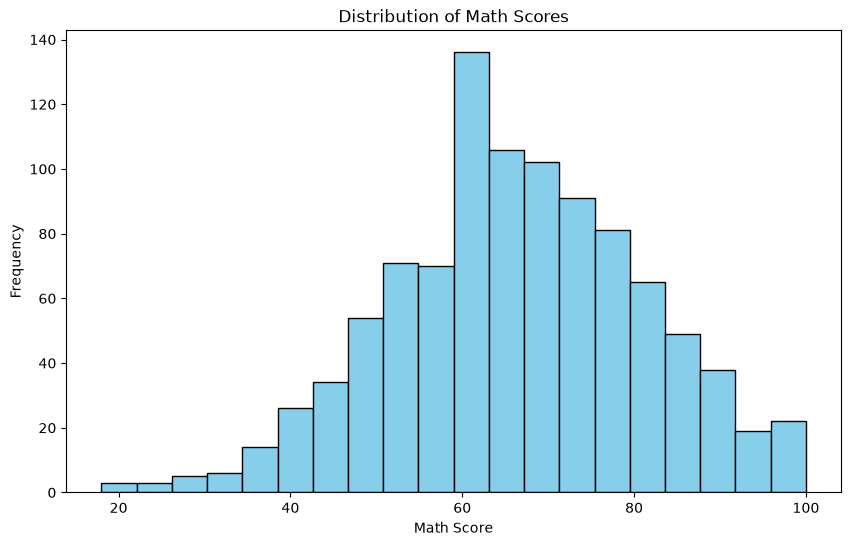

Interpretation: The distribution of math scores is approximately bell-shaped and centered around 66, with most students scoring between 55 and 80 and a slight tail toward lower scores.



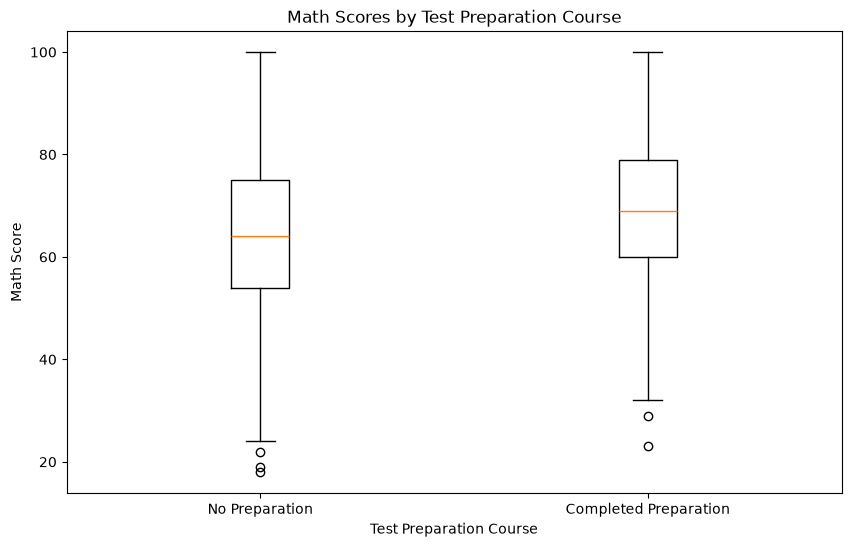

Interpretation: Students who completed the test preparation course have a noticeably higher median math score and shifted interquartile range compared to students who did not complete the course.



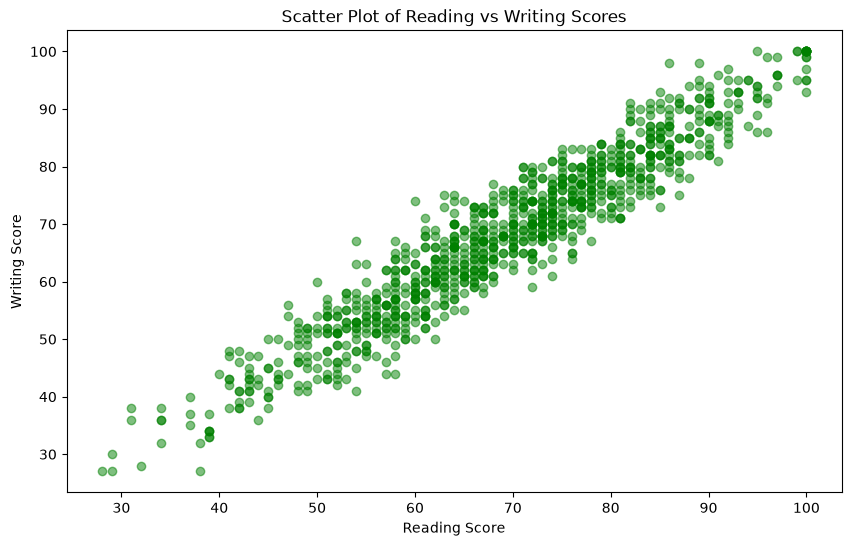

Interpretation: The scatter plot shows a tight, positive linear relationship between reading and writing scores. As reading scores increase, writing scores increase proportionally.



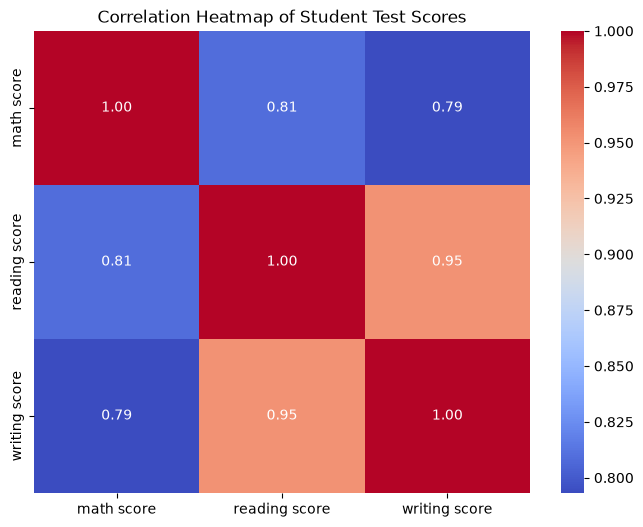

Interpretation: The correlation heatmap shows strong positive correlations across all three test subjects, with Reading and Writing having the strongest correlation (0.95), followed by Math and Reading (0.81) and Math and Writing (0.80).


In [5]:
# Q2D

# 1. Distribution plot for math score
plt.figure(figsize=(10, 6))
plt.hist(dataset['math score'], bins=20, color='skyblue', edgecolor='black')
plt.xlabel('Math Score')
plt.ylabel('Frequency')
plt.title('Distribution of Math Scores')
plt.show()
print(
    'Interpretation: The distribution of math scores is approximately bell-shaped'
    ' and centered around 66, with most students scoring between 55 and 80 and'
    ' a slight tail toward lower scores.\n'
)

# 2. Boxplot for math score by test preparation course
plt.figure(figsize=(10, 6))
plt.boxplot(
    [
        dataset[dataset['test preparation course'] == 'none']['math score'],
        dataset[dataset['test preparation course'] == 'completed'][
            'math score'
        ],
    ],
    tick_labels=['No Preparation', 'Completed Preparation'],
)
plt.xlabel('Test Preparation Course')
plt.ylabel('Math Score')
plt.title('Math Scores by Test Preparation Course')
plt.show()
print(
    'Interpretation: Students who completed the test preparation course have a'
    ' noticeably higher median math score and shifted interquartile range'
    ' compared to students who did not complete the course.\n'
)

# 3. Scatter plot for reading score vs writing score
plt.figure(figsize=(10, 6))
plt.scatter(
    dataset['reading score'],
    dataset['writing score'],
    color='green',
    alpha=0.5,
)
plt.xlabel('Reading Score')
plt.ylabel('Writing Score')
plt.title('Scatter Plot of Reading vs Writing Scores')
plt.show()
print(
    'Interpretation: The scatter plot shows a tight, positive linear'
    ' relationship between reading and writing scores. As reading scores'
    ' increase, writing scores increase proportionally.\n'
)

# 4. Correlation heatmap for scores
plt.figure(figsize=(8, 6))
sns.heatmap(
    dataset[['math score', 'reading score', 'writing score']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
)
plt.title('Correlation Heatmap of Student Test Scores')
plt.show()
print(
    'Interpretation: The correlation heatmap shows strong positive correlations'
    ' across all three test subjects, with Reading and Writing having the'
    ' strongest correlation (0.95), followed by Math and Reading (0.81) and'
    ' Math and Writing (0.80).'
)

In [6]:
# Q2E

# 1. Calculating and printing descriptive statistics for math scores
mean_math = dataset['math score'].mean()
median_math = dataset['math score'].median()
variance_math = dataset['math score'].var()
std_math = dataset['math score'].std()
quartiles_math = dataset['math score'].quantile([0.25, 0.5, 0.75])

print('--- Overall Math Score Descriptive Statistics ---')
print(f'Mean:               {mean_math:.2f}')
print(f'Median:             {median_math:.2f}')
print(f'Variance:           {variance_math:.2f}')
print(f'Standard Deviation: {std_math:.2f}')
print(f'Quartiles:\n{quartiles_math}\n')

math_completed = dataset[dataset['test preparation course'] == 'completed'][
    'math score'
]
math_none = dataset[dataset['test preparation course'] == 'none']['math score']
print(f'Mean Math Score (Completed Prep): {math_completed.mean():.2f}')
print(f'Mean Math Score (No Prep):        {math_none.mean():.2f}\n')

# 2 & 3. State H0 and H1
print(
    'H0: There is no statistically significant difference in mean math scores'
    ' between students who completed the test preparation course and those who'
    ' did not (mu_completed = mu_none).'
)
print(
    'H1: There is a statistically significant difference in mean math scores'
    ' between students who completed the test preparation course and those who'
    ' did not (mu_completed != mu_none).\n'
)

# 4. Select and justify an appropriate hypothesis test
print(
    'Test Selection Justification: A two-sample independent t-test (ttest_ind)'
    ' is appropriate because we are comparing the sample means of a continuous'
    ' numerical variable (math score) between two independent groups of'
    ' students (completed test preparation vs. no test preparation).\n'
)

# 5, 6, 7, & 8. Calculate test statistic and p-value, make decision, and interpret
alpha = 0.05
t_stat, pvalue = ttest_ind(math_completed, math_none)
print(f'Significance level (alpha): {alpha}')
print(f't-statistic: {t_stat:.4f}')
print(f'p-value: {pvalue:.4e}\n')

if pvalue < alpha:
  print(
      f'Decision: Reject H0 (p-value = {pvalue:.4e} < {alpha}). There is a'
      ' statistically significant difference in mean math scores between the'
      ' two groups.'
  )
  print(
      'Interpretation: Students who completed the test preparation course have'
      f' a significantly higher mean math score ({math_completed.mean():.2f})'
      ' compared to those who did not complete the course'
      f' ({math_none.mean():.2f}). This indicates a positive association'
      ' between completing the preparation course and higher math performance,'
      ' though statistical significance alone does not prove direct causation'
      ' without controlling for confounding factors like prior academic'
      ' preparation or student motivation.'
  )
else:
  print(
      'Decision: Fail to reject H0. There is no statistically significant'
      ' difference in math scores between the two groups.'
  )

--- Overall Math Score Descriptive Statistics ---
Mean:               66.32
Median:             66.00
Variance:           219.15
Standard Deviation: 14.80
Quartiles:
0.25    57.0
0.50    66.0
0.75    77.0
Name: math score, dtype: float64

Mean Math Score (Completed Prep): 69.70
Mean Math Score (No Prep):        64.43

H0: There is no statistically significant difference in mean math scores between students who completed the test preparation course and those who did not (mu_completed = mu_none).
H1: There is a statistically significant difference in mean math scores between students who completed the test preparation course and those who did not (mu_completed != mu_none).

Test Selection Justification: A two-sample independent t-test (ttest_ind) is appropriate because we are comparing the sample means of a continuous numerical variable (math score) between two independent groups of students (completed test preparation vs. no test preparation).

Significance level (alpha): 0.05
t-statist